# Window-steered attention for limited-angle sinogram completion

This notebook introduces one idea and gives you the tools to test it.

**The idea.** In a sinogram, two projections taken at different angles are related through the object. The acquisition geometry does not tell us *how* (that depends on the unknown object), but it tells us exactly *which* detector bins of one projection can possibly share mass with a given bin of the other. We call this set the **window**. We propose to use the window as a hard attention mask between projections, and to learn only what happens inside it.

**What is in the notebook**

1. Motivation and notation
2. The geometry of the window, with an interactive figure
3. Numerical checks: the window really contains all the mass, and the exact transport kernel can be computed for a known object
4. Window-steered attention: mask, geometric bias, a NumPy reference implementation and a PyTorch layer
5. Caveats and open questions
6. A proposed sequence of experiments

**Requirements:** `numpy`, `matplotlib`, `ipywidgets` (for the sliders). PyTorch is only needed for the layer in section 4.3.

## 1. Motivation and notation

**Problem.** Digital breast tomosynthesis (DBT) acquires projections over a short angular range (roughly 60° in total) at low dose, so the data are both limited-angle and noisy. We want to *complete* (and denoise) the sinogram before reconstruction. We start with the simplest setting: 2D, parallel beam, synthetic data.

**Why not simply use a CNN?** A CNN or UNet treats the angle axis and the detector axis like the two axes of an ordinary image. In a sinogram they are not equivalent: each point of the object draws a sinusoid across all angles, so the natural neighbourhoods of a sinogram are sinusoidal strips and not rectangles.

**Why not a plain GNN?** A graph with one node per angle and the detector row as node feature is natural, but if messages between neighbouring rows are formed by aggregating bins *at the same detector position*, the rows are compared as if their detector axes were aligned. They are not: bin $s$ at one angle and bin $s$ at another angle see different parts of the object. (Whether this is the main reason such models underperform is a hypothesis to be tested.)

**Where the Helgason–Ludwig consistency conditions (HLCC) fit.** For a consistent sinogram $g(s,\phi)$ the moments
$$M_n(\phi)=\int g(s,\phi)\,s^n\,ds$$
are homogeneous polynomials of degree $n$ in $(\cos\phi,\sin\phi)$. This is a *global* condition on the whole angular range: a single projection or a pair of projections does not violate it. It is therefore useful as a loss on a completed sinogram or as an evaluation metric, but it cannot drive node-local message passing. Computed from a short arc the coefficients are also badly conditioned, and the high-order moments amplify noise. The architecture below does not use the HLCC; it uses a different, local piece of geometry.

**Notation.**

- A point of the object has image coordinates $(x,y)$. At projection angle $\phi$ it falls on detector coordinate $s=x\cos\phi+y\sin\phi$ and has coordinate $t=-x\sin\phi+y\cos\phi$ *along* the ray.
- $g(s,\phi)=\int f\,dt$ is the line integral of the object $f\ge 0$ along the ray $(s,\phi)$.
- We take the object to lie inside a disk of radius $\rho$ around the isocentre, and normalise the detector so that $s\in[-1,1]$, $\rho\le 1$.
- We compare two angles $\phi_i$ and $\phi_j=\phi_i+\Delta$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, TEAL = "#378ADD", "#D85A30", "#1D9E75"

## 2. The geometry of the window

Take a point with coordinates $(s,t)$ in the frame of angle $\phi_i$, that is $x=s\cos\phi_i-t\sin\phi_i$ and $y=s\sin\phi_i+t\cos\phi_i$. Seen from angle $\phi_j=\phi_i+\Delta$ it falls on the detector coordinate

$$s'=x\cos\phi_j+y\sin\phi_j=s\cos\Delta+t\sin\Delta .$$

Two lines at different angles intersect in exactly one point, and $t$ is the position of that point along the first line. So **bin $s$ at $\phi_i$ and bin $s'$ at $\phi_j$ can only share mass if their lines intersect inside the object.**

If the object is inside a disk of radius $\rho$, the ray $(s,\phi_i)$ crosses it only for $|t|\le\sqrt{\rho^2-s^2}$. Hence

$$\boxed{\;|\,s'-s\cos\Delta\,|\;\le\;\sqrt{\rho^2-s^2}\;|\sin\Delta|\;}$$

This is the **window** $W(s)$ of bin $s$: the exact set of bins of the second projection that may receive mass from bin $s$ of the first one, whatever the object is.

In [2]:
def window(s, delta, rho=1.0):
    """Window [lo, hi] of destination bins s' for a source bin s (or an array of s)."""
    s = np.asarray(s, dtype=float)
    half = np.sqrt(np.clip(rho**2 - s**2, 0.0, None)) * abs(np.sin(delta))
    centre = s * np.cos(delta)
    return centre - half, centre + half


def intersection_t(s, sp, delta):
    """Position t along the ray (s, phi_i) of the intersection with the ray (s', phi_j)."""
    return (sp - s * np.cos(delta)) / np.sin(delta)

### 2.1 Interactive figure

The **left panel** is image space, drawn in the frame where the detector at $\phi_i$ is horizontal.

- The blue line is the ray of bin $s$ at $\phi_i$; its thick part is the chord inside the object.
- The orange line is the detector axis at $\phi_j$. The dashed orange lines are the rays at $\phi_j$ through the two ends of the chord, and the thick orange segment is where they hit the axis. Every other point of the chord lands between them: that segment is the window.

The **right panel** is the plane of pairs $(s,s')$. The teal region is the union of all windows, i.e. all allowed pairs; the vertical slice at the chosen $s$ is the window of that bin.

Things to try:

1. Move $s$ to the edge of the object: the chord shrinks to a point and the window collapses.
2. Set $s=0$ and increase $\Delta$: the window is at its widest, because the chord is longest there.
3. Set $\Delta=0$: the allowed region collapses onto the diagonal, each bin can only map to itself. At $\Delta=90^\circ$ it fills a disk.
4. Reduce $\rho$ (a small object near the centre): all windows shrink.

In [11]:
def draw_window(delta_deg=20.0, s0=0.2, rho=1.0, axes=None):
    delta = np.deg2rad(delta_deg)
    cD, sD = np.cos(delta), np.sin(delta)
    if axes is None:
        fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.6))
    axL, axR = axes
    axL.clear(); axR.clear()

    # ---------------- left: image space
    th = np.linspace(0, 2 * np.pi, 300)
    axL.plot(np.cos(th), np.sin(th), color="0.7", lw=0.8, ls="--")                 # detector extent
    axL.fill(rho * np.cos(th), rho * np.sin(th), color="0.93", ec="0.4", lw=1)     # object support
    axL.plot([-1.25, 1.25], [0, 0], color=BLUE, lw=1)                              # detector at phi_i
    axL.text(1.22, -0.1, r"detector at $\phi_i$ ($s$)", color=BLUE, ha="right", va="top", fontsize=9)
    u = np.array([cD, sD])
    axL.plot([-1.25 * u[0], 1.25 * u[0]], [-1.25 * u[1], 1.25 * u[1]], color=ORANGE, lw=1)  # detector at phi_j
    axL.text(1.25 * u[0], 1.25 * u[1] + 0.05, r"detector at $\phi_j$ ($s'$)", color=ORANGE, ha="center", fontsize=9)
    axL.plot([s0, s0], [-1.15, 1.15], color=BLUE, lw=1, ls=(0, (4, 3)))            # ray of bin s

    if abs(s0) <= rho:
        c = np.sqrt(max(rho**2 - s0**2, 0.0))
        axL.plot([s0, s0], [-c, c], color=BLUE, lw=4, solid_capstyle="round")      # chord
        lo, hi = window(s0, delta, rho)
        for t_end, sp in ((-c, s0 * cD - c * sD), (c, s0 * cD + c * sD)):
            foot = sp * u
            axL.plot([s0, foot[0]], [t_end, foot[1]], color=ORANGE, lw=1, ls=(0, (4, 3)))
            axL.plot(s0, t_end, "o", color=ORANGE, ms=4)
        a, b = min(lo, hi), max(lo, hi)
        axL.plot([a * u[0], b * u[0]], [a * u[1], b * u[1]], color=ORANGE, lw=5, solid_capstyle="round")
    else:
        axL.text(0, 0, "this ray misses the object", ha="center", color="crimson")
    axL.set_xlim(-1.45, 1.45); axL.set_ylim(-1.45, 1.45); axL.set_aspect("equal"); axL.axis("off")
    axL.set_title("Image space", fontsize=10, color="0.35")

    # ---------------- right: (s, s') plane
    ph = np.linspace(0, 2 * np.pi, 400)
    axR.fill(rho * np.cos(ph), rho * np.cos(ph - delta), color=TEAL, alpha=0.22)
    axR.plot(rho * np.cos(ph), rho * np.cos(ph - delta), color=TEAL, lw=1.2)
    axR.plot([-1, 1], [-1, 1], color="0.6", ls=":", lw=1)
    axR.axvline(s0, color=BLUE, ls=(0, (4, 3)), lw=1)
    if abs(s0) <= rho:
        lo, hi = window(s0, delta, rho)
        axR.plot([s0, s0], [lo, hi], color=ORANGE, lw=5, solid_capstyle="round")
        axR.plot(s0, s0 * cD, "o", color="k", ms=3)
    axR.set_xlim(-1, 1); axR.set_ylim(-1, 1); axR.set_aspect("equal")
    axR.set_xlabel(r"$s$ (bin at $\phi_i$)"); axR.set_ylabel(r"$s'$ (bin at $\phi_j$)")
    axR.set_title("Allowed pairs (teal) and window of the chosen bin (orange)", fontsize=10, color="0.35")
    if abs(s0) <= rho:
        w = hi - lo
        axR.text(0.03, 0.03, f"window: centre {s0*cD:+.2f}, width {w:.2f}  (= {w*128:.0f} of 256 bins)",
                 transform=axR.transAxes, fontsize=8.5, color="0.2",
                 bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.85))
    return axes


# interactive version
sl_delta = widgets.FloatSlider(value=20, min=0, max=90, step=1, description="Δ (deg)", continuous_update=True)
sl_s = widgets.FloatSlider(value=0.2, min=-1, max=1, step=0.01, description="s")
sl_rho = widgets.FloatSlider(value=1.0, min=0.2, max=1.0, step=0.01, description="ρ")
fig_i, axes_i = plt.subplots(1, 2, figsize=(9.5, 4.6))
plt.close(fig_i)   # shown through the widget output, not twice

out = widgets.Output()
def _update(_=None):
    with out:
        out.clear_output(wait=True)
        draw_window(sl_delta.value, sl_s.value, sl_rho.value, axes_i)
        display(fig_i)
for w in (sl_delta, sl_s, sl_rho):
    w.observe(_update, names="value")
display(widgets.VBox([widgets.HBox([sl_delta, sl_s, sl_rho]), out]))
_update()

### 2.2 The same figure, without widgets

If the sliders do not render in your viewer (for example on a static preview), here are three fixed values of $\Delta$ at the same bin $s=0.2$.

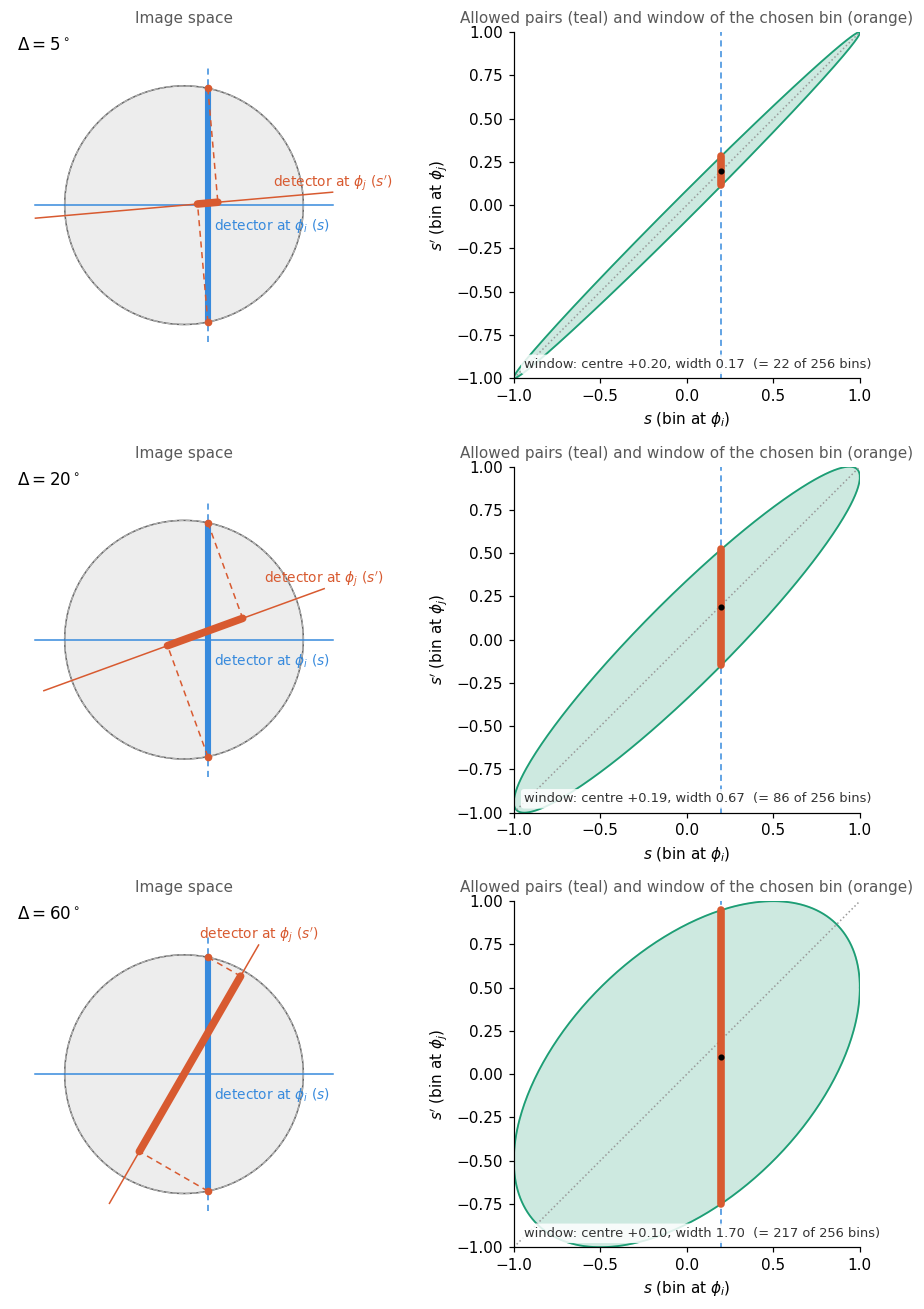

In [12]:
fig, axs = plt.subplots(3, 2, figsize=(9, 12))
for row, d in zip(axs, (5, 20, 60)):
    draw_window(d, 0.2, 1.0, axes=row)
    row[0].text(-1.4, 1.3, rf"$\Delta={d}^\circ$", fontsize=11)
plt.tight_layout(); plt.show()

### 2.3 What to take from the figure

- The window is **centred on $s\cos\Delta$**, so it drifts slightly towards the middle of the detector.
- Its **width is largest at the centre of the detector and zero at the edge of the object**: there the ray only grazes the object.
- Its width scales with $|\sin\Delta|$. With $N=256$ bins and $\rho=1$ (the full detector), the width at the centre is $N|\sin\Delta|$ bins: about 9 bins for $\Delta=2^\circ$, 44 for $10^\circ$, 128 for $30^\circ$.
- The set of all allowed pairs is an **ellipse**: with $s=\rho\cos\theta$, $s'=\rho\cos(\theta-\Delta)$.
- The window is a **hard support constraint**. It says nothing about how the mass of bin $s$ is split inside it.

Three equivalent readings of the same statement:

1. *Intersection inside the object.* A pair $(s,s')$ is allowed exactly when the two rays meet where $f$ can be non-zero.
2. *Sinusoids.* The intersection point traces a sinusoid in the sinogram that passes through both bins. A pair is allowed exactly when some sinusoid of a point inside the object connects them.
3. *Transport.* For $f\ge 0$ and equal total mass at every angle, the two rows are related by a transport plan supported in the window (next section).

## 3. Numerical checks

### 3.1 Is the window correct?

We sample many points uniformly in a disk of radius $\rho$, project each point to the two angles, and check that every pair $(s,s')$ falls inside the window.

largest distance outside the window: 0.00e+00   (0 up to floating point = window is exact)


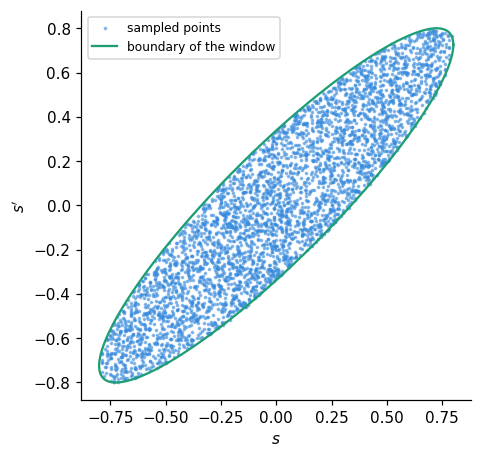

In [6]:
rng = np.random.default_rng(0)

def sample_disk(n, rho):
    r = rho * np.sqrt(rng.random(n)); a = 2 * np.pi * rng.random(n)
    return r * np.cos(a), r * np.sin(a)

rho = 0.8
x, y = sample_disk(200_000, rho)
phi_i, delta = np.deg2rad(30), np.deg2rad(25)
phi_j = phi_i + delta
s  = x * np.cos(phi_i) + y * np.sin(phi_i)
sp = x * np.cos(phi_j) + y * np.sin(phi_j)

lo, hi = window(s, delta, rho)
violation = np.maximum(lo - sp, sp - hi).max()
print(f"largest distance outside the window: {max(violation, 0):.2e}   (0 up to floating point = window is exact)")

fig, ax = plt.subplots(figsize=(4.6, 4.6))
ax.scatter(s[:4000], sp[:4000], s=2, color=BLUE, alpha=0.5, label="sampled points")
ph = np.linspace(0, 2 * np.pi, 400)
ax.plot(rho * np.cos(ph), rho * np.cos(ph - delta), color=TEAL, lw=1.5, label="boundary of the window")
ax.set_xlabel(r"$s$"); ax.set_ylabel(r"$s'$"); ax.set_aspect("equal"); ax.legend(fontsize=8, loc="upper left")
plt.show()

### 3.2 The exact transport kernel of a known object

For a non-negative object the exact kernel is the object's profile along the ray, reparametrised. Along the ray $(s,\phi_i)$, $s'$ is linear in $t$ with $ds'=|\sin\Delta|\,dt$, so

$$K(s'\mid s)=\frac{f\big(s,\,t(s')\big)}{|\sin\Delta|\;g_i(s)},\qquad g_j(s')=\int g_i(s)\,K(s'\mid s)\,ds .$$

$K$ is non-negative, sums to 1 over $s'$ (mass conservation) and vanishes outside the window. The product $J(s,s')=g_i(s)K(s'\mid s)$ is a *coupling* with marginals $g_i$ and $g_j$.

We can compute $J$ directly for any discretised object by binning every pixel by its pair $(s,s')$. This is the **oracle kernel**: what a perfect model of the interaction between two rows would know.

rows of K sum to 1 (where g_i>0): True
g_j = g_i @ K: True
fraction of coupling mass outside the window (+- 1 bin): 1.23e-09


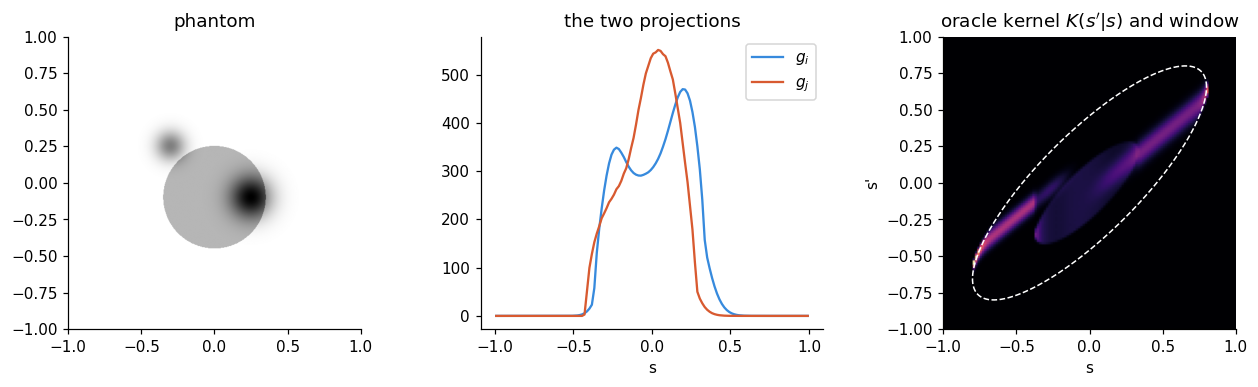

In [7]:
def phantom(X, Y, rho=0.8):
    f = (np.exp(-((X - 0.25) ** 2 + (Y + 0.10) ** 2) / 0.02)
         + 0.7 * np.exp(-((X + 0.30) ** 2 + (Y - 0.25) ** 2) / 0.01)
         + 0.4 * ((X ** 2 + (Y + 0.1) ** 2) < 0.35 ** 2))
    f[X ** 2 + Y ** 2 > rho ** 2] = 0.0
    return f

M, N = 512, 128                       # image size, number of detector bins
xs = (np.arange(M) + 0.5) / M * 2 - 1
X, Y = np.meshgrid(xs, xs)
f = phantom(X, Y)

edges = np.linspace(-1, 1, N + 1); centres = 0.5 * (edges[1:] + edges[:-1])
phi_i, delta = np.deg2rad(10), np.deg2rad(35); phi_j = phi_i + delta
si = X * np.cos(phi_i) + Y * np.sin(phi_i)
sj = X * np.cos(phi_j) + Y * np.sin(phi_j)

def splat2d(u, v, w, N):
    """Joint histogram of (u, v) in [-1, 1]^2 with bilinear splitting between neighbouring bins
    (smoother than nearest-bin counting, which aliases on a pixel grid)."""
    a = (u.ravel() + 1) / 2 * N - 0.5;  b = (v.ravel() + 1) / 2 * N - 0.5
    a0, b0 = np.floor(a).astype(int), np.floor(b).astype(int)
    fa, fb = a - a0, b - b0
    J = np.zeros((N, N)); w = w.ravel()
    for da, wa in ((0, 1 - fa), (1, fa)):
        for db, wb in ((0, 1 - fb), (1, fb)):
            ia, ib = a0 + da, b0 + db
            ok = (ia >= 0) & (ia < N) & (ib >= 0) & (ib < N)
            J += np.bincount(ia[ok] * N + ib[ok], weights=(w * wa * wb)[ok], minlength=N * N).reshape(N, N)
    return J

J = splat2d(si, sj, f, N)
g_i, g_j = J.sum(1), J.sum(0)
K = np.divide(J, g_i[:, None], out=np.zeros_like(J), where=g_i[:, None] > 1e-12)

print("rows of K sum to 1 (where g_i>0):", np.allclose(K.sum(1)[g_i > 1e-12], 1))
print("g_j = g_i @ K:", np.allclose(g_i @ K, g_j))

# fraction of mass outside the window (tolerance: one bin, because of the splitting between neighbouring bins)
S, SP = np.meshgrid(centres, centres, indexing="ij")
lo, hi = window(S, delta, rho=0.8)
tol = 2 / N          # one bin: bilinear splitting spreads mass by up to one bin
outside = ((SP < lo - tol) | (SP > hi + tol))
print(f"fraction of coupling mass outside the window (+- 1 bin): {J[outside].sum() / J.sum():.2e}")

fig, axs = plt.subplots(1, 3, figsize=(12, 3.6))
axs[0].imshow(f, origin="lower", extent=[-1, 1, -1, 1], cmap="gray_r"); axs[0].set_title("phantom")
axs[1].plot(centres, g_i, color=BLUE, label=r"$g_i$"); axs[1].plot(centres, g_j, color=ORANGE, label=r"$g_j$")
axs[1].set_title("the two projections"); axs[1].legend(); axs[1].set_xlabel("s")
axs[2].imshow(K.T, origin="lower", extent=[-1, 1, -1, 1], cmap="magma", aspect="equal")
ph = np.linspace(0, 2 * np.pi, 400)
axs[2].plot(0.8 * np.cos(ph), 0.8 * np.cos(ph - delta), color="white", lw=1, ls="--")
axs[2].set_title(r"oracle kernel $K(s'|s)$ and window"); axs[2].set_xlabel("s"); axs[2].set_ylabel("s'")
plt.tight_layout(); plt.show()

Notice that the kernel is *not* uniform in the window: it is large where the object is large along the ray, and zero where the object is absent. The window is the geometric envelope; the content of $K$ is the unknown object. Predicting $K$ (or something that plays its role) from the features of the two rows is what the network has to learn.

## 4. Window-steered attention

**Graph.** One node per projection angle; the node feature is the detector row (or a learned embedding of each bin, shape $N\times C$). An edge $(i,j)$ carries its angular difference $\Delta$. Measured nodes are clamped to their measured (or denoised) values; missing nodes start from a rough initialisation.

**Message passing on an edge.** Every bin $s$ of node $i$ is a query. Its keys are only the bins $s'$ of node $j$ that lie in the window $W(s)$:

$$\alpha(s\to s')=\operatorname*{softmax}_{s'\in W(s)}\Big(\tfrac{q_i(s)\cdot k_j(s')}{\sqrt d}+b(t,\Delta)\Big),\qquad m_i(s)=\sum_{s'\in W(s)}\alpha(s\to s')\,v_j(s').$$

- The softmax over the window gives non-negative weights summing to 1, exactly the normalisation of the transport kernel $K$.
- The window is symmetric, so the same mask serves the reverse direction $j\to i$.
- **Geometric bias.** For every allowed pair the intersection position $t=(s'-s\cos\Delta)/\sin\Delta$ is known. Passing $t$ (and $\Delta$) to the logits through $b$ tells the network *where in the object* the two bins meet, which is what the kernel depends on.

| Fixed by the acquisition geometry | Learned from data |
| --- | --- |
| Which bin pairs may interact (the window) | How mass is split inside the window |
| Intersection position $t$ for each allowed pair | Bin features, and their dependence on $t$ and $\Delta$ |
| Window width as a function of $s$, $\Delta$, object size | How evidence from different edges is combined |

Each bin attends to roughly $N|\sin\Delta|$ bins instead of $N$, so the layer is cheaper than full attention, and the mask carries information the network would otherwise have to discover from data.

### 4.1 The mask

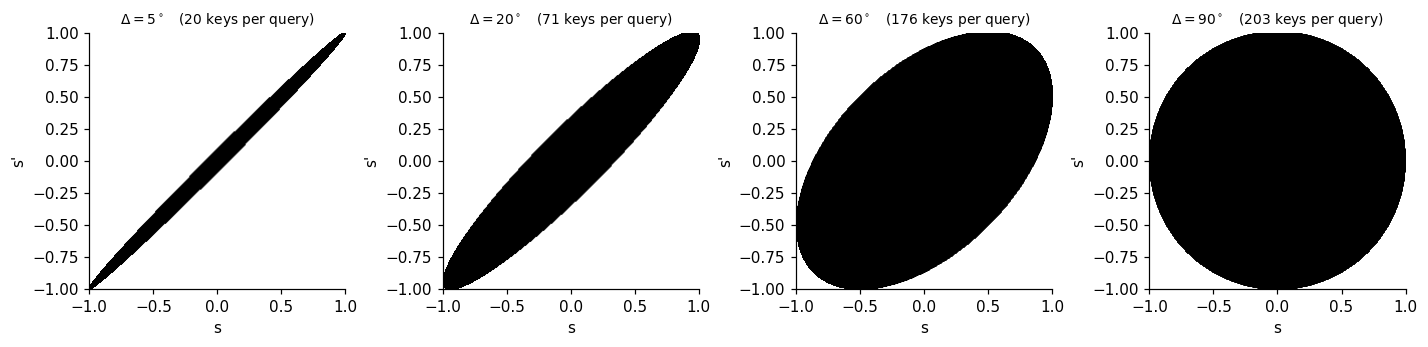

width of the window at the detector centre (bins), N=256, rho=1, no tolerance:
  Delta= 2 deg:    9 bins   (formula N*sin(Delta) = 9)
  Delta=10 deg:   45 bins   (formula N*sin(Delta) = 44)
  Delta=30 deg:  128 bins   (formula N*sin(Delta) = 128)


In [8]:
def window_mask(N, delta, rho=1.0, tol_bins=1.0):
    """Boolean (N, N) mask M[k, l] = True if bin l of the target row is in the window of bin k of the source row.
    Also returns the intersection position t[k, l] for every pair (0 where sin(delta)=0).
    tol_bins widens the window by that many bins to absorb discretisation."""
    c = (np.arange(N) + 0.5) / N * 2 - 1
    S, SP = c[:, None], c[None, :]
    half = np.sqrt(np.clip(rho**2 - S**2, 0.0, None)) * abs(np.sin(delta))
    centre = S * np.cos(delta)
    mask = np.abs(SP - centre) <= half + tol_bins * 2 / N
    t = (SP - centre) / np.sin(delta) if abs(np.sin(delta)) > 1e-9 else np.zeros((N, N))
    return mask, t

N = 256
fig, axs = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, d in zip(axs, (5, 20, 60, 90)):
    m, t = window_mask(N, np.deg2rad(d))
    ax.imshow(m.T, origin="lower", cmap="Greys", extent=[-1, 1, -1, 1])
    ax.set_title(rf"$\Delta={d}^\circ$   ({m.sum(1).mean():.0f} keys per query)", fontsize=9)
    ax.set_xlabel("s"); ax.set_ylabel("s'")
plt.tight_layout(); plt.show()

print("width of the window at the detector centre (bins), N=256, rho=1, no tolerance:")
for d in (2, 10, 30):
    m, _ = window_mask(N, np.deg2rad(d), tol_bins=0)
    print(f"  Delta={d:>2} deg: {m[N//2].sum():>4} bins   (formula N*sin(Delta) = {N*np.sin(np.deg2rad(d)):.0f})")

### 4.2 A NumPy reference implementation (forward pass only)

This is a deliberately small single-head version. It is meant to be read, and to check the properties that matter: the weights are supported in the window and sum to one.

In [9]:
def softmax_masked(logits, mask):
    z = np.where(mask, logits, -np.inf)
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)                       # exp(-inf) = 0 outside the window
    return e / e.sum(axis=1, keepdims=True)

def window_attention_np(x_i, x_j, mask, t, delta, params):
    """x_i, x_j: (N, C) features of the two rows. Returns messages into the bins of row i, and the weights."""
    Wq, Wk, Wv, wb = params
    q, k, v = x_i @ Wq, x_j @ Wk, x_j @ Wv
    d = q.shape[1]
    bias = wb[0] * t + wb[1] * t**2 + wb[2] * t * delta          # b(t, Delta): a simple learnable form
    logits = q @ k.T / np.sqrt(d) + bias
    alpha = softmax_masked(logits, mask)
    return alpha @ v, alpha

rng = np.random.default_rng(1)
N, C, d = 128, 8, 8
params = (rng.normal(size=(C, d)) / np.sqrt(C), rng.normal(size=(C, d)) / np.sqrt(C),
          rng.normal(size=(C, d)) / np.sqrt(C), rng.normal(size=3))
x_i, x_j = rng.normal(size=(N, C)), rng.normal(size=(N, C))
delta = np.deg2rad(25)
mask, t = window_mask(N, delta)
msg, alpha = window_attention_np(x_i, x_j, mask, t, delta, params)

print("message shape:", msg.shape)
print("weights sum to 1 per query:", np.allclose(alpha.sum(1), 1))
print("weight outside the window:", alpha[~mask].sum())
print("keys per query: mean %.1f, max %d  (full attention would use %d)" % (mask.sum(1).mean(), mask.sum(1).max(), N))

message shape: (128, 8)
weights sum to 1 per query: True
weight outside the window: 0.0
keys per query: mean 44.3, max 56  (full attention would use 128)


### 4.3 A PyTorch layer

The same layer, batched and multi-head. The mask and $t$ depend only on $(N,\Delta,\rho)$, so they can be precomputed once per distinct $\Delta$ and cached. The cell is guarded so that the notebook still runs without PyTorch.

In [10]:
try:
    import torch, torch.nn as nn
    HAVE_TORCH = True
except Exception as e:           # also catches broken installations
    HAVE_TORCH = False
    print("PyTorch not available, skipping this cell:", type(e).__name__)

if HAVE_TORCH:
    class WindowAttention(nn.Module):
        """Multi-head attention from the bins of row j (keys/values) to the bins of row i (queries),
        restricted to the geometric window. mask, t: (N, N) tensors precomputed from window_mask."""
        def __init__(self, dim, heads=4):
            super().__init__()
            assert dim % heads == 0
            self.h, self.dk = heads, dim // heads
            self.q, self.k, self.v, self.o = (nn.Linear(dim, dim) for _ in range(4))
            self.bias = nn.Sequential(nn.Linear(2, 16), nn.GELU(), nn.Linear(16, heads))   # b(t, Delta) per head

        def forward(self, x_i, x_j, mask, t, delta):
            B, N, _ = x_i.shape
            split = lambda z: z.view(B, N, self.h, self.dk).transpose(1, 2)               # (B, h, N, dk)
            q, k, v = split(self.q(x_i)), split(self.k(x_j)), split(self.v(x_j))
            logits = q @ k.transpose(-1, -2) / self.dk ** 0.5                              # (B, h, N, N)
            feats = torch.stack([t, torch.full_like(t, float(delta))], dim=-1)             # (N, N, 2)
            logits = logits + self.bias(feats).permute(2, 0, 1)[None]                      # (1, h, N, N)
            logits = logits.masked_fill(~mask[None, None], float("-inf"))
            attn = logits.softmax(dim=-1)
            out = (attn @ v).transpose(1, 2).reshape(B, N, -1)
            return self.o(out), attn

    N, C = 128, 32
    delta = np.deg2rad(25)
    m_np, t_np = window_mask(N, delta)
    mask_t, t_t = torch.tensor(m_np), torch.tensor(t_np, dtype=torch.float32)
    layer = WindowAttention(C, heads=4)
    xi, xj = torch.randn(2, N, C), torch.randn(2, N, C)
    out, attn = layer(xi, xj, mask_t, t_t, delta)
    print("output:", tuple(out.shape), "  attention:", tuple(attn.shape))
    print("weight outside the window:", float(attn.masked_select(~mask_t[None, None].expand_as(attn)).sum()))

output: (2, 128, 32)   attention: (2, 4, 128, 128)
weight outside the window: 0.0


## 5. Caveats and open questions

The mask is exact, but it does not solve the problem on its own. These are the points where the idea can fail, and each one should become an experiment.

- **Small angular differences are weakly informative.** Because $t$ is divided by $\sin\Delta$, for neighbouring angles one bin of $s'$ moves the intersection a long way along the ray. Close angles say little about where along the ray the mass sits; far-apart angles say a lot, at the price of wider windows. Restricting edges to small $\Delta$ is probably a mistake.
- **Edges are predicted independently.** All the kernels $K(i,j)$ derive from one single object, so they are strongly mutually constrained, but each edge predicts its own weights. Stacking layers is a way to approximate the consistency; an explicit constraint, or the HLCC as a loss on the completed sinogram, is another.
- **Missing nodes start from a poor initialisation.** Their queries are weak in the first layers, so information has to flow from the measured nodes outwards. Whether a few layers suffice for a large angular gap is an empirical question.
- **Limited angle is intrinsically hard.** For compactly supported objects the problem is injective but severely ill-posed, so completion injects a learned prior rather than recovering lost information. Results should be judged against that, and a 60° range in parallel beam (120° of the 180° missing) is very harsh; start with milder ranges.
- **The hard support assumes the object is inside the field of view.** Otherwise there is lateral truncation, mass is not conserved across angles and the window can be violated. A tighter support than a disk (for example a breast silhouette) narrows the window, and the half-length of the chord can be estimated from the sinogram.
- **Noise.** The exact statements need non-negative data with the same total mass at every angle. Noisy or denoised sinograms violate this slightly, so the mask is applied to learned features and mass conservation is treated as a soft property.
- **Cone beam.** The forward geometry carries over: only the set of sampled lines changes (a magnification factor enters the window). What changes is invertibility, and a projection mixes axial planes. Solve 2D first.
- **Sheaf language.** The construction is a set of per-edge linear maps with a hard geometric support, and can be presented as masked attention. If a sheaf formulation is wanted, the restriction maps are these windowed kernels; however, the sheaf Laplacian energy $\sum\|F_{ij}g_i-F_{ji}g_j\|^2$ should *not* be used as a loss with learned blurring kernels, because it is minimised trivially by making them very wide.

## 6. Proposed investigation

Each step can falsify the idea cheaply before the next one costs more. Decide in advance what result would make you drop it.

1. **Data and setup.** Synthetic phantoms (ellipses first, then natural or medical images downscaled), 2D parallel-beam sinograms, objects fully inside the field of view. Generate and reconstruct with different discretisations (avoid the inverse crime). Add Poisson noise for low dose. Use angular ranges of 120°–150° first, then shrink towards 60°.
2. **Check the window numerically** on your own projector (section 3.1). If the support is violated, find out why before going on: discretisation, truncation, wrong object radius, off-centre rotation axis.
3. **Oracle kernel** (section 3.2). With the phantom known, compute the exact $K$ and verify $g_j=K^\top g_i$. This gives the upper limit for any predicted kernel, and ground truth for the attention weights.
4. **One masked-attention layer on a pairwise task.** Predict row $j$ from row $i$ (then from several rows) with all angles available. Visualise the attention weights against the true intersection positions. Compare with unmasked attention, with a plain shift baseline, and with a learned mask of the same size. *If the mask gives no benefit over unmasked attention at equal parameters, stop here.*
5. **Full model for completion.** Stack layers, clamp the measured nodes, train on limited-angle input with the full sinogram as target. Ablate: mask vs no mask, geometric bias on/off, edge set (short, long, all), depth, parameter count.
6. **Baselines and metrics.** Filtered backprojection on the partial sinogram, UNet, UNet + HLCC loss, a plain GNN, optionally a ViT with sinusoidal patches. Report PSNR/SSIM of the completed sinogram on the missing angles, the same after reconstruction, the HLCC violation of the completed sinogram, at several noise levels and angular ranges.
7. **Denoising.** Test the same architecture on denoising of the measured angles, where the redundancy between rows is the signal.
8. **Extensions.** Fan beam, then cone beam (including the mixing between axial planes), then real DBT data.

## References

- Helgason–Ludwig consistency conditions for limited-angle tomography: [code](https://github.com/YixingHuang/Helgason-Ludwig-consistency-conditions-for-limited-angle-tomography/tree/main) and [paper](https://www5.informatik.uni-erlangen.de/Forschung/Publikationen/2017/Huang_RMD2017.pdf).
- Sheaf neural networks, background only: [arXiv:2202.01379](https://arxiv.org/pdf/2202.01379).

These are the starting points of the project. This list has not been checked against a literature search: please add the relevant tomography, consistency-condition and attention papers yourself, and verify any citation before using it.